# SupplyPulse Intelligence — Session 1, Task 4: Exploratory analysis

**Historical M5 sales; reproducible, sampled analytics — NOT a demand forecast.**

- Original files: Kaggle M5 `sales_train_validation.csv`, `calendar.csv`, `sell_prices.csv`, provided by the user under the competition's access terms.
- Analysis subset: first three product-store series in every `(store_id, department)` group across ten stores and seven departments (**210 nonrandom series**).
- The following comparisons **must not be extrapolated** to full-Walmart sales, typical stores or true unconstrained demand. No observed inventory, supplier lead times, stockouts, or profit are contained in these inputs.
- Both the plots and their tables come from `scripts/generate_eda.py`, where they are reconciled with the previously independently checked Task 3 SQL outputs.

To rebuild: `python -m src.pipeline --sample-per-store-dept 3`, `python -m src.analysis --database data/processed/m5.sqlite`, `python -m scripts.generate_eda`, then execute this notebook.


In [1]:
from pathlib import Path
import json
import sqlite3
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
if not (root / 'scripts' / 'generate_eda.py').exists():
    raise FileNotFoundError('Open this notebook from the repository root or notebooks/ directory.')
sys.path.insert(0, str(root))
from scripts.generate_eda import collect_eda, check_eda, plot_chart, build_review

database = root / 'data' / 'processed' / 'm5.sqlite'
if not database.exists():
    raise FileNotFoundError('Missing local real-data warehouse; run the ingestion pipeline from README.md.')
with sqlite3.connect(database) as db:
    frames = collect_eda(db)
    checked = check_eda(db, frames, root / 'reports' / 'tables')
print('Nonrandom sample verification:',json.dumps(checked,indent=2))


Nonrandom sample verification: {
  "scope": "Nonrandom prefix sample: do not generalize to retailer",
  "rows": 401730,
  "series": 210,
  "stores": 10,
  "units": 210786,
  "zero_rows": 299476,
  "zero_pct": 74.54658601548303,
  "priced_rows": 330309,
  "priced_pct": 82.22164140094092,
  "missing_price_rows": 71421,
  "first_date": "2011-01-29",
  "last_date": "2016-04-24",
  "charts": 6,
  "references_reconciled": [
    "monthly_units",
    "store_units",
    "category_units",
    "weekday_mean",
    "zero_share"
  ]
}


## Monthly observed unit rate

The chart uses **complete calendar months only** and a product-store-day denominator. The full detail table retains the partial boundary months; 2011-01 and 2016-04 are omitted from the trend. This prevents plotting partial months as artificial declines. Historical changes are not forecasts.

**Read alongside:** `reports/eda_business_review.md` for measured results and limits.

,month,dates_observed,series_days,units,units_per_series_day,complete_month
0,2011-01,3,630,251,0.398413,False
1,2011-02,28,5880,2357,0.400850,True
2,2011-03,31,6510,2468,0.379109,True
3,2011-04,30,6300,2390,0.379365,True
4,2011-05,31,6510,2674,0.410753,True
5,2011-06,30,6300,2914,0.462540,True
6,2011-07,31,6510,2578,0.396006,True
7,2011-08,31,6510,2268,0.348387,True
8,2011-09,30,6300,1980,0.314286,True
9,2011-10,31,6510,2032,0.312135,True


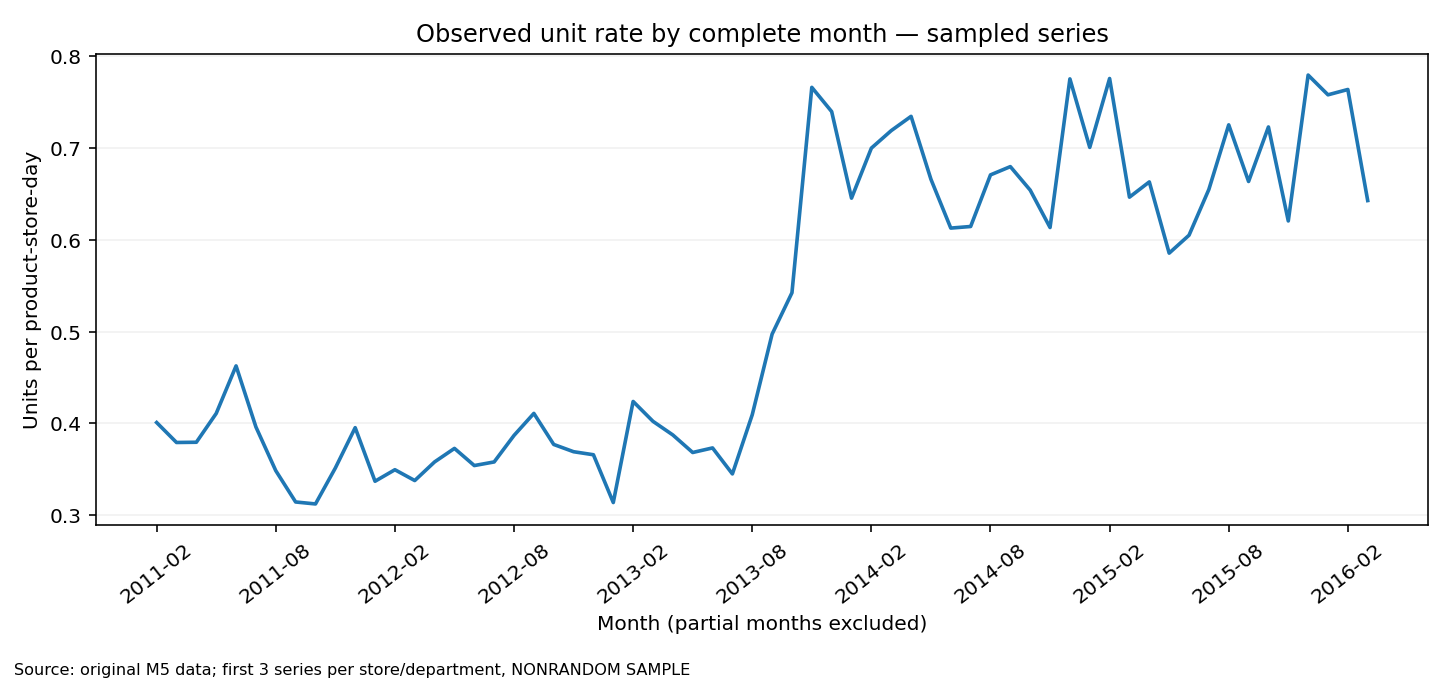

In [2]:
tag = 'monthly_units'
df = frames[tag].copy()
display(df.head(12))
plot = root / 'reports' / 'figures' / f'{tag}.png'
plot.parent.mkdir(parents=True, exist_ok=True)
plot_chart(tag, df, plot)
display(Image(filename=str(plot)))


## Store-level observed unit rate

Rates account for the same number of sampled series-days per store. The underlying items were **not selected randomly**, so the chart is not a ranking of all products or entire stores.

**Read alongside:** `reports/eda_business_review.md` for measured results and limits.

,store_id,series_days,item_count,units,units_per_series_day
0,CA_1,40173,21,19899,0.495333
1,CA_2,40173,21,19767,0.492047
2,CA_3,40173,21,29096,0.724268
3,CA_4,40173,21,13331,0.331840
4,TX_1,40173,21,14393,0.358275
5,TX_2,40173,21,16262,0.404799
6,TX_3,40173,21,15535,0.386703
7,WI_1,40173,21,28860,0.718393
8,WI_2,40173,21,30370,0.755980
9,WI_3,40173,21,23273,0.579319


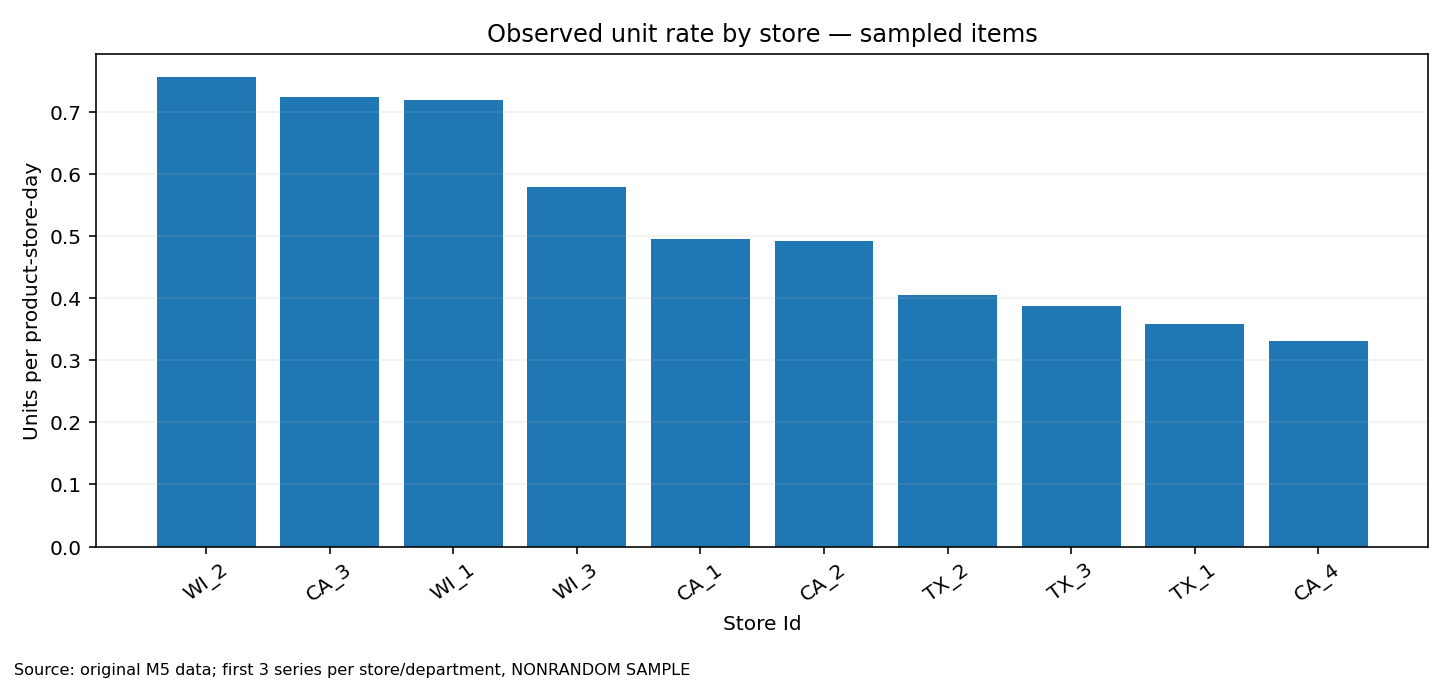

In [3]:
tag = 'store_units'
df = frames[tag].copy()
display(df.head(12))
plot = root / 'reports' / 'figures' / f'{tag}.png'
plot.parent.mkdir(parents=True, exist_ok=True)
plot_chart(tag, df, plot)
display(Image(filename=str(plot)))


## Category-level observed unit rate

Use per-series-day rates, **not raw unit totals**, because the seven departments belong to categories with different sample sizes. No causality or population representativeness is established.

**Read alongside:** `reports/eda_business_review.md` for measured results and limits.

,category,series_days,units,units_per_series_day
0,FOODS,172170,137627,0.799367
1,HOBBIES,114780,22226,0.193640
2,HOUSEHOLD,114780,50933,0.443745


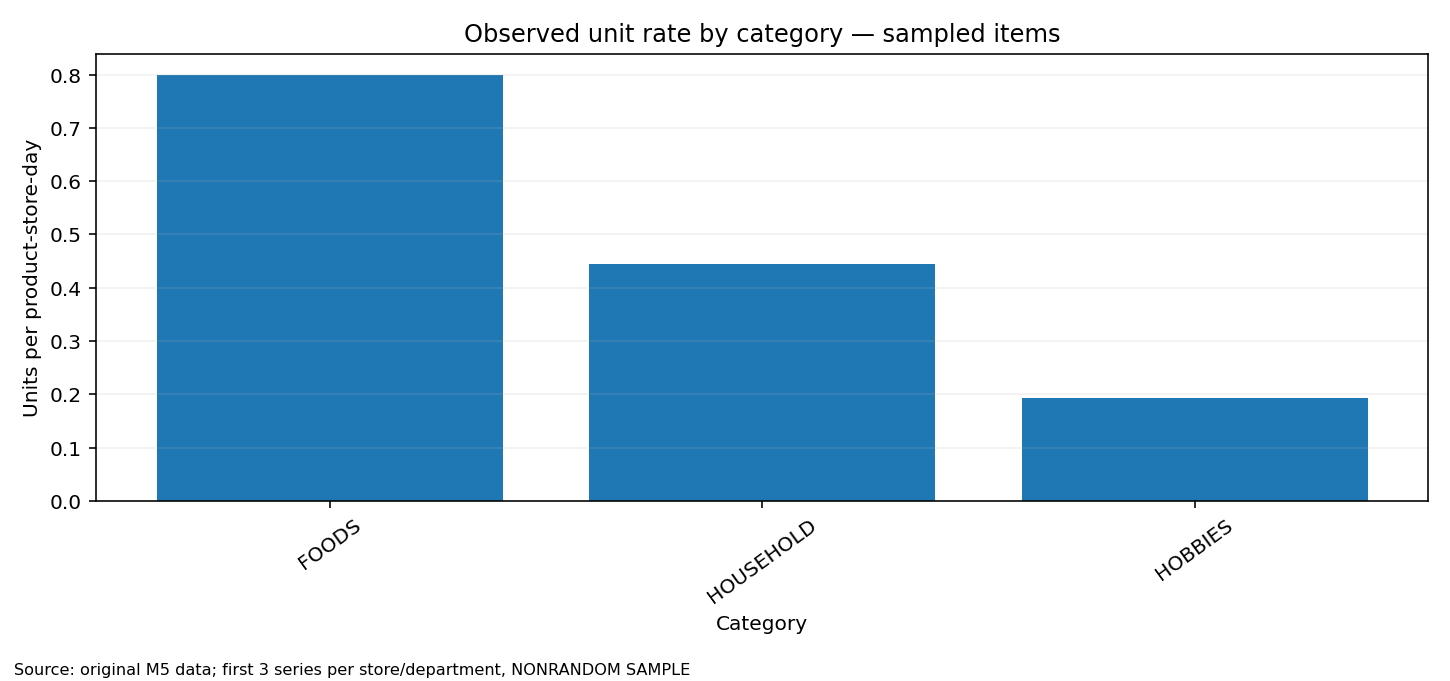

In [4]:
tag = 'category_units'
df = frames[tag].copy()
display(df.head(12))
plot = root / 'reports' / 'figures' / f'{tag}.png'
plot.parent.mkdir(parents=True, exist_ok=True)
plot_chart(tag, df, plot)
display(Image(filename=str(plot)))


## Weekday and weekend patterns

Averages use total observed product-store-days per weekday as the denominator. Saturdays and Sundays have different counts than some weekdays. Differences are descriptive, not causal effects.

**Read alongside:** `reports/eda_business_review.md` for measured results and limits.

,weekday,series_days,units,units_per_series_day
0,Monday,57330,28683,0.500314
1,Tuesday,57330,27225,0.474882
2,Wednesday,57330,26552,0.463143
3,Thursday,57330,26539,0.462916
4,Friday,57330,29511,0.514757
5,Saturday,57540,36425,0.633038
6,Sunday,57540,35851,0.623062


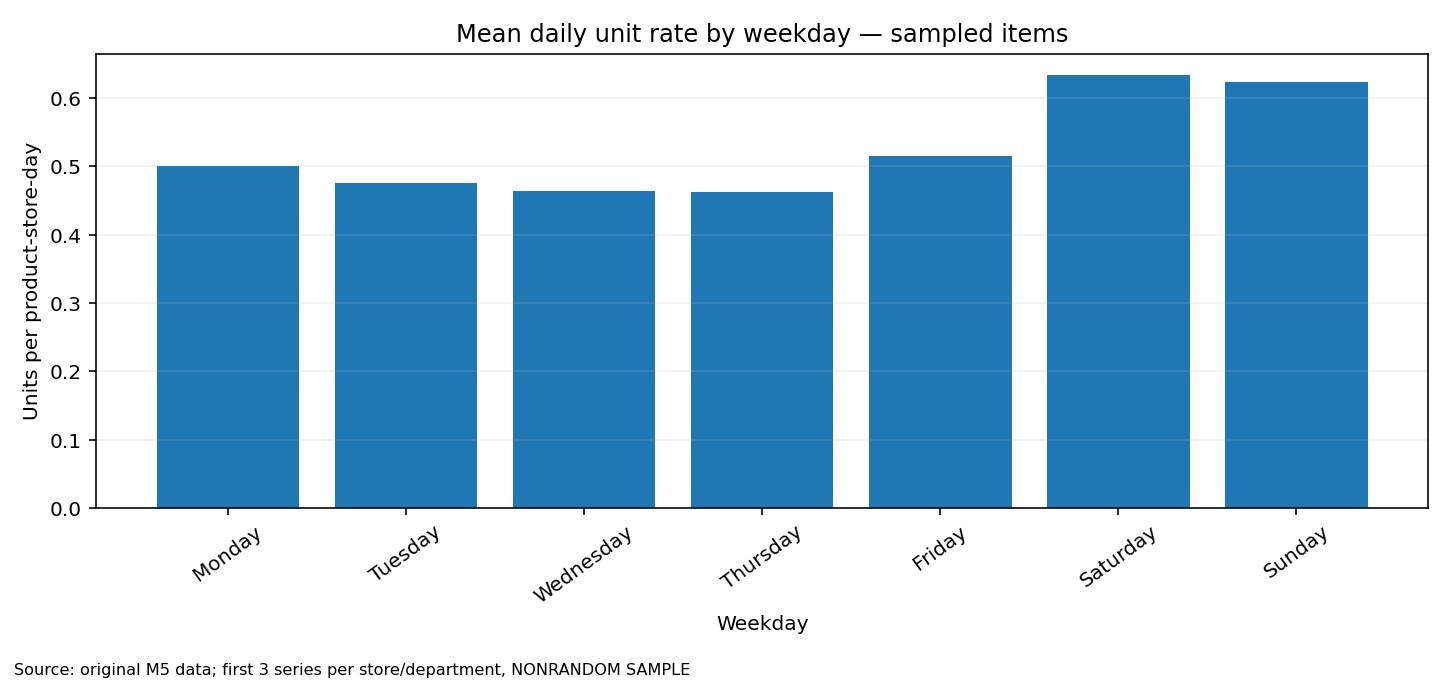

In [5]:
tag = 'weekday_mean'
df = frames[tag].copy()
display(df.head(12))
plot = root / 'reports' / 'figures' / f'{tag}.png'
plot.parent.mkdir(parents=True, exist_ok=True)
plot_chart(tag, df, plot)
display(Image(filename=str(plot)))


## Share of zero-unit sales days

A zero-sales observation does **not** show a stockout. We lack on-hand inventory, product availability and replenishment records. The percentages are fractions of sampled product-store-days.

**Read alongside:** `reports/eda_business_review.md` for measured results and limits.

,store_id,series_days,zero_days,zero_pct
0,CA_1,40173,29035,72.274911
1,CA_2,40173,29454,73.317900
2,CA_3,40173,26517,66.007020
3,CA_4,40173,32054,79.789909
4,TX_1,40173,31279,77.860752
5,TX_2,40173,30026,74.741742
6,TX_3,40173,30761,76.571329
7,WI_1,40173,28714,71.475867
8,WI_2,40173,31063,77.323078
9,WI_3,40173,30573,76.103353


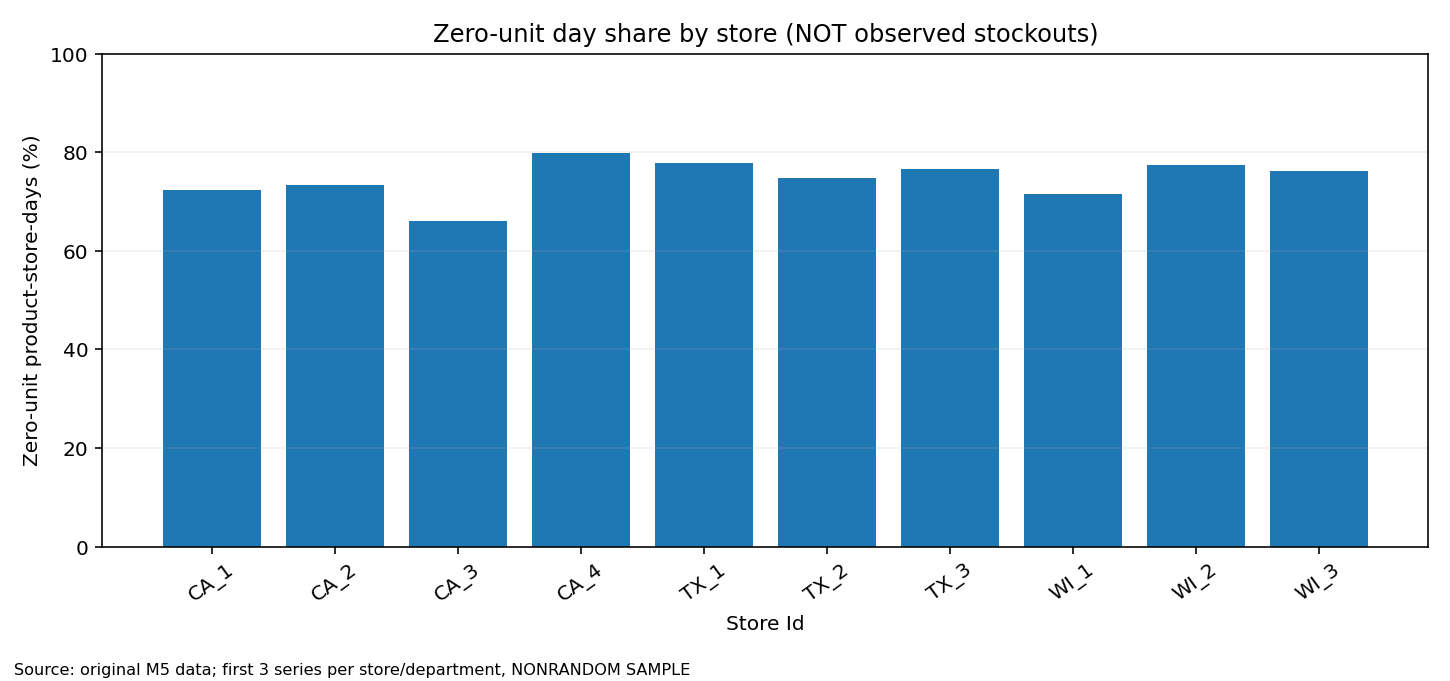

In [6]:
tag = 'zero_share'
df = frames[tag].copy()
display(df.head(12))
plot = root / 'reports' / 'figures' / f'{tag}.png'
plot.parent.mkdir(parents=True, exist_ok=True)
plot_chart(tag, df, plot)
display(Image(filename=str(plot)))


## Historical selling-price matching coverage

A missing matched weekly price is **not zero revenue** or necessarily a data error. The plotted share is the proportion of sample product-store-days with an observed weekly sell price. Unmatched days must be excluded from priced-revenue estimates.

**Read alongside:** `reports/eda_business_review.md` for measured results and limits.

,store_id,series_days,priced_days,priced_pct
0,CA_1,40173,34034,84.718592
1,CA_2,40173,30170,75.100192
2,CA_3,40173,33278,82.836731
3,CA_4,40173,32270,80.327583
4,TX_1,40173,34020,84.683743
5,TX_2,40173,33985,84.596620
6,TX_3,40173,34097,84.875414
7,WI_1,40173,32487,80.867747
8,WI_2,40173,31913,79.438927
9,WI_3,40173,34055,84.770866


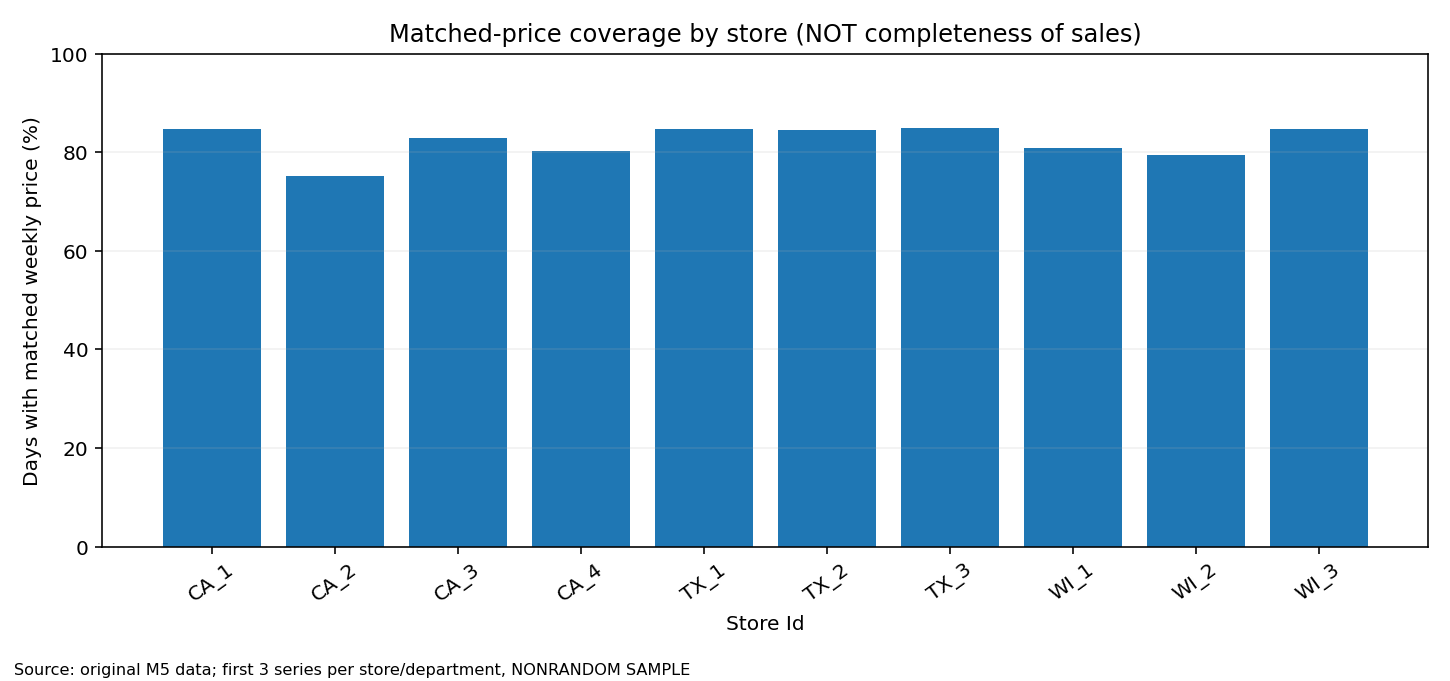

In [7]:
tag = 'price_coverage'
df = frames[tag].copy()
display(df.head(12))
plot = root / 'reports' / 'figures' / f'{tag}.png'
plot.parent.mkdir(parents=True, exist_ok=True)
plot_chart(tag, df, plot)
display(Image(filename=str(plot)))


## Verified business interpretation

**Avoid overstating these associations.** The notebook does not demonstrate a causal weekend effect, confirmed stockouts, official financial performance, or inventory savings. Forecasting must be evaluated on a chronologically separated test window in a later session.

In [8]:
display(Markdown(build_review(frames, checked)))

# SupplyPulse — Session 1, Task 4: Verified exploratory review

All results below apply **only to the 210 deterministically chosen product-store series** in the local M5 sample (three first-listed series per store/department).
This is a **nonrandom, nonrepresentative** sample; differences are descriptive and are **not** full-Walmart estimates or causal effects.

## Scope and data integrity

- Observations: **401,730** product-store-days, **210** series, **10** stores, 2011-01-29 to 2016-04-24.
- Observed unit sales: **210,786**; zero-unit days: **299,476 (74.55%)**.
- Available weekly-price matches: **330,309 (82.22%)**; unmatched-price days: **71,421**.
- All six plotted series sum correctly to the relevant warehouse totals; **5 chart datasets** match independently reconciled Task 3 query exports.

## Evidence-backed findings and limitations

### 1. Monthly observed unit rate

- The trend chart uses **62 complete months** and plots units per product-store-day to avoid mistaking different month lengths for changing demand.
- Boundary months excluded from the line: 2011-01 (3 days), 2016-04 (24 days).
- The series is descriptive, with possible product lifecycle, promotion, prices, and changing availability mixed together. It is **not** a forecast or isolated seasonal effect.

### 2. Store comparison

- Largest observed sample rate: **WI_2**, **0.756** units per product-store-day (**30,370** units).
- Smallest: **CA_4**, **0.332** units per product-store-day (**13,331** units).
- Each store has the same number of sampled series, but this does not establish population-wide store rankings.

### 3. Product category

- Highest observed per-series-day rate: **FOODS**, **0.799** units. Lowest: **HOBBIES**, **0.194** units.
- Comparisons use *rates*, not category total units, since categories contain different numbers of sampled item-store series.

### 4. Weekday pattern

- Weekend days averaged **0.628** units per series-day; Monday–Friday averaged **0.483** (**30.0% higher** in this sample).
- This is an observed association, not evidence that weekend timing causes a sales lift.

### 5. Zero-unit share

- The highest zero-day share was **CA_4** at **79.79%**; the lowest was **CA_3** at **66.01%**.
- A zero sale can reflect no purchase demand, shelf absence, product lifecycle, or other factors. **Stockout frequency cannot be inferred** without inventory records.

### 6. Weekly selling-price coverage

- Lowest observed weekly-price matching share: **CA_2** at **75.10%**; highest: **TX_3** at **84.88%**.
- A missing weekly price is not evidence of a free sale, unavailable product, or data corruption. Revenue can be computed only for matched observations.

## Business interpretation for an interview

- Prioritize **investigating** store/category/day-of-week heterogeneity on a better-designed representative panel; do not roll out changes using sample ranks alone.
- Before inventory policy modeling, obtain or explicitly simulate lead times, available stock, replenishment rules and costs. Never label simulated savings as achieved.
- Forecasting work should establish chronological holdouts, a simple baseline, and leakage checks; avoid fitting models on the holdout interval.

## Reproduction and evidence

`python -m scripts.generate_eda --database data/processed/m5.sqlite --sql-exports reports/tables`

- Six figure PNGs: `reports/figures/`.
- Six plotting-input tables: `reports/eda_tables/`.
- Machine-readable summary: `reports/eda_review.json`.
- Interactive executed notebook: `notebooks/01_exploratory_analysis.ipynb`.
- Task 3 source-to-SQL verification: `reports/sql_python_reconciliation.json`.
